In [14]:
# CAREER NAVIGATOR
# Baseline Model Development

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import json
import warnings

from pathlib import Path

warnings.filterwarnings("ignore")

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    confusion_matrix,
    classification_report
)

RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd().parent

PROCESSED_DIR = PROJECT_ROOT / "dataset" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
REPORT_DIR = PROJECT_ROOT / "reports" / "evaluation"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Baseline Model Development Environment Ready!")
print("Project:", PROJECT_ROOT)

Baseline Model Development Environment Ready!
Project: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator


In [15]:
# Load feature matrices

X_train = np.load(PROCESSED_DIR / "X_train.npy")
X_val = np.load(PROCESSED_DIR / "X_val.npy")
X_test = np.load(PROCESSED_DIR / "X_test.npy")

# Load placement targets

y_train_placement = np.load(PROCESSED_DIR / "y_train_placement.npy")
y_val_placement = np.load(PROCESSED_DIR / "y_val_placement.npy")
y_test_placement = np.load(PROCESSED_DIR / "y_test_placement.npy")

# Load career readiness targets

y_train_readiness = np.load(PROCESSED_DIR / "y_train_readiness.npy")
y_val_readiness = np.load(PROCESSED_DIR / "y_val_readiness.npy")
y_test_readiness = np.load(PROCESSED_DIR / "y_test_readiness.npy")

# Load career domain targets

y_train_domain = np.load(PROCESSED_DIR / "y_train_domain.npy")
y_val_domain = np.load(PROCESSED_DIR / "y_val_domain.npy")
y_test_domain = np.load(PROCESSED_DIR / "y_test_domain.npy")

# Load employability targets

y_train_employability = np.load(PROCESSED_DIR / "y_train_employability.npy")
y_val_employability = np.load(PROCESSED_DIR / "y_val_employability.npy")
y_test_employability = np.load(PROCESSED_DIR / "y_test_employability.npy")

print("Datasets loaded successfully!")

print("\nFeature dimensions:")
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Datasets loaded successfully!

Feature dimensions:
Training: (10500, 65)
Validation: (2250, 65)
Testing: (2250, 65)


In [16]:
print("PLACEMENT DISTRIBUTION")
print(pd.Series(y_train_placement).value_counts().sort_index())

print("\nCAREER READINESS DISTRIBUTION")
print(pd.Series(y_train_readiness).value_counts().sort_index())

print("\nCAREER DOMAIN DISTRIBUTION")
print(pd.Series(y_train_domain).value_counts().sort_index())

print("\nEMPLOYABILITY SCORE SUMMARY")
print(pd.Series(y_train_employability).describe())

PLACEMENT DISTRIBUTION
0    6672
1    3828
Name: count, dtype: int64

CAREER READINESS DISTRIBUTION
0    2608
1    2619
2    5273
Name: count, dtype: int64

CAREER DOMAIN DISTRIBUTION
0    1115
1    1072
2    2063
3    1078
4    3872
5    1300
Name: count, dtype: int64

EMPLOYABILITY SCORE SUMMARY
count    10500.000000
mean        55.373917
std          6.909867
min         29.440001
25%         50.680000
50%         55.250000
75%         60.009998
max         82.769997
dtype: float64


In [17]:
classification_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

print("Classification models initialized:")
for name in classification_models:
    print("-", name)

Classification models initialized:
- Logistic Regression
- Decision Tree
- Random Forest


In [18]:
def evaluate_classifier(model, X, y, task_name):
    predictions = model.predict(X)

    results = {
        "Task": task_name,
        "Model": model.__class__.__name__,
        "Accuracy": accuracy_score(y, predictions),
        "Precision_Macro": precision_score(
            y, predictions, average="macro", zero_division=0
        ),
        "Recall_Macro": recall_score(
            y, predictions, average="macro", zero_division=0
        ),
        "F1_Macro": f1_score(
            y, predictions, average="macro", zero_division=0
        ),
        "F1_Weighted": f1_score(
            y, predictions, average="weighted", zero_division=0
        ),
        "ROC_AUC": np.nan
    }

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X)

        try:
            if len(model.classes_) == 2:
                results["ROC_AUC"] = roc_auc_score(
                    y, probabilities[:, 1]
                )
            else:
                results["ROC_AUC"] = roc_auc_score(
                    y,
                    probabilities,
                    multi_class="ovr",
                    average="macro",
                    labels=model.classes_
                )
        except ValueError:
            pass

    return results

In [19]:
classification_tasks = {
    "Placement": (y_train_placement, y_val_placement),
    "Career Readiness": (y_train_readiness, y_val_readiness),
    "Career Domain": (y_train_domain, y_val_domain)
}

classification_results = []
trained_classifiers = {}

for task_name, (y_train, y_val) in classification_tasks.items():

    print(f"\n{'=' * 65}")
    print(f"TRAINING MODELS: {task_name.upper()}")
    print("=" * 65)

    trained_classifiers[task_name] = {}

    for model_name, model in classification_models.items():

        print(f"\nTraining {model_name}...")

        model.fit(X_train, y_train)

        results = evaluate_classifier(
            model,
            X_val,
            y_val,
            task_name
        )

        results["Model"] = model_name
        classification_results.append(results)

        trained_classifiers[task_name][model_name] = model

        model_filename = (
            f"baseline_{task_name.lower().replace(' ', '_')}_"
            f"{model_name.lower().replace(' ', '_')}.joblib"
        )

        joblib.dump(
            model,
            MODEL_DIR / model_filename
        )

        print(f"Accuracy: {results['Accuracy']:.4f}")
        print(f"Macro F1: {results['F1_Macro']:.4f}")
        print(f"ROC-AUC: {results['ROC_AUC']:.4f}"
              if not np.isnan(results["ROC_AUC"])
              else "ROC-AUC: Not available")

print("\nAll classification models trained successfully!")


TRAINING MODELS: PLACEMENT

Training Logistic Regression...
Accuracy: 0.6493
Macro F1: 0.5308
ROC-AUC: 0.6488

Training Decision Tree...
Accuracy: 0.5747
Macro F1: 0.5386
ROC-AUC: 0.5385

Training Random Forest...
Accuracy: 0.6516
Macro F1: 0.5175
ROC-AUC: 0.6324

TRAINING MODELS: CAREER READINESS

Training Logistic Regression...
Accuracy: 0.7769
Macro F1: 0.7746
ROC-AUC: 0.9138

Training Decision Tree...
Accuracy: 0.5964
Macro F1: 0.5937
ROC-AUC: 0.6863

Training Random Forest...
Accuracy: 0.7329
Macro F1: 0.7207
ROC-AUC: 0.8848

TRAINING MODELS: CAREER DOMAIN

Training Logistic Regression...
Accuracy: 0.4244
Macro F1: 0.2669
ROC-AUC: 0.6853

Training Decision Tree...
Accuracy: 0.2458
Macro F1: 0.1835
ROC-AUC: 0.5114

Training Random Forest...
Accuracy: 0.4067
Macro F1: 0.1716
ROC-AUC: 0.6456

All classification models trained successfully!


In [20]:
classification_df = pd.DataFrame(classification_results)

classification_df = classification_df.sort_values(
    by=["Task", "F1_Macro"],
    ascending=[True, False]
).reset_index(drop=True)

display(
    classification_df.round(4)
)

,Task,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,ROC_AUC
0,Career Domain,Logistic Regression,0.4244,0.3367,0.2689,0.2669,0.3663,0.6853
1,Career Domain,Decision Tree,0.2458,0.1848,0.1830,0.1835,0.2507,0.5114
2,Career Domain,Random Forest,0.4067,0.4027,0.2100,0.1716,0.2934,0.6456
3,Career Readiness,Logistic Regression,0.7769,0.7884,0.7640,0.7746,0.7766,0.9138
4,Career Readiness,Random Forest,0.7329,0.7688,0.6962,0.7207,0.7295,0.8848
5,Career Readiness,Decision Tree,0.5964,0.5940,0.5935,0.5937,0.5964,0.6863
6,Placement,Decision Tree,0.5747,0.5388,0.5385,0.5386,0.5736,0.5385
7,Placement,Logistic Regression,0.6493,0.6081,0.5538,0.5308,0.5947,0.6488
8,Placement,Random Forest,0.6516,0.6174,0.5490,0.5175,0.5864,0.6324


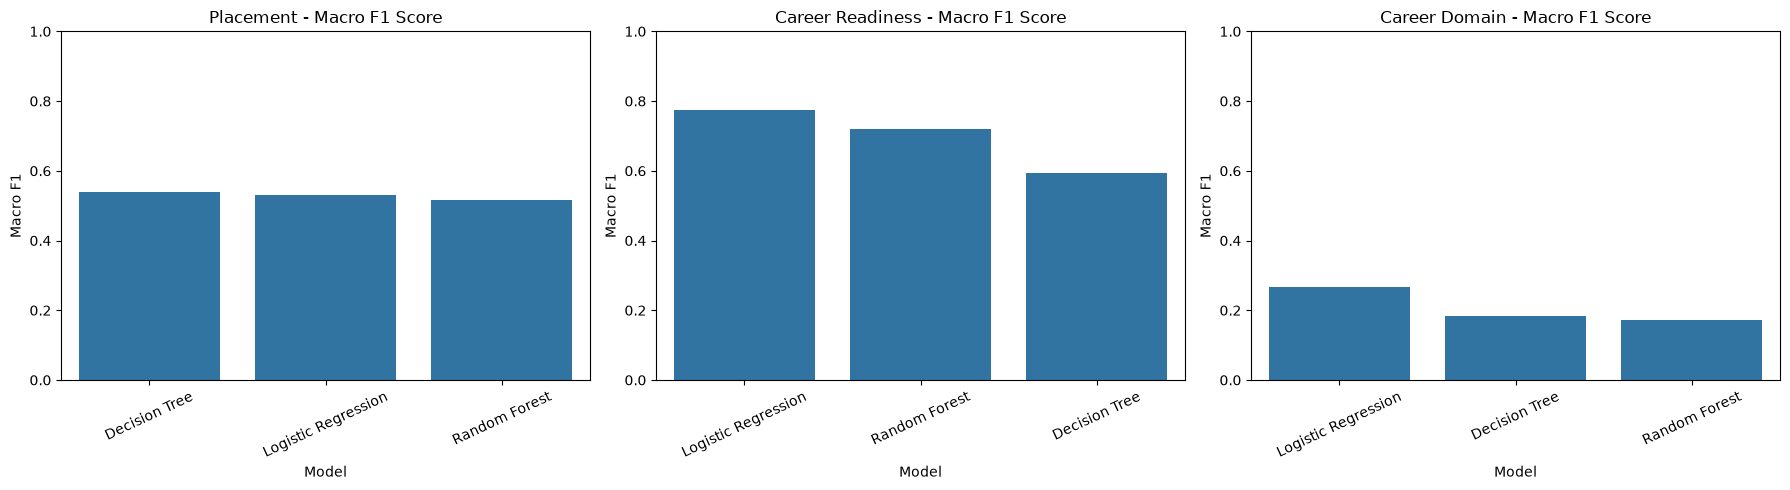

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

tasks = ["Placement", "Career Readiness", "Career Domain"]

for ax, task in zip(axes, tasks):

    task_data = classification_df[
        classification_df["Task"] == task
    ]

    sns.barplot(
        data=task_data,
        x="Model",
        y="F1_Macro",
        ax=ax
    )

    ax.set_title(f"{task} - Macro F1 Score")
    ax.set_xlabel("Model")
    ax.set_ylabel("Macro F1")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

In [22]:
classification_path = (
    REPORT_DIR / "baseline_classification_results.csv"
)

classification_df.to_csv(
    classification_path,
    index=False
)

print("Classification results saved successfully!")
print(classification_path)

Classification results saved successfully!
d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\reports\evaluation\baseline_classification_results.csv


In [23]:
regression_models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )
}

print("Regression models initialized:")
for name in regression_models:
    print("-", name)

Regression models initialized:
- Linear Regression
- Decision Tree
- Random Forest


In [24]:
def evaluate_regressor(model, X, y, task_name):

    predictions = model.predict(X)

    return {
        "Task": task_name,
        "Model": model.__class__.__name__,
        "MAE": mean_absolute_error(y, predictions),
        "MSE": mean_squared_error(y, predictions),
        "RMSE": np.sqrt(mean_squared_error(y, predictions)),
        "R2": r2_score(y, predictions)
    }

In [25]:
regression_results = []
trained_regressors = {}

for model_name, model in regression_models.items():

    print(f"\nTraining {model_name}...")

    model.fit(X_train, y_train_employability)

    results = evaluate_regressor(
        model,
        X_val,
        y_val_employability,
        "Employability Score"
    )

    results["Model"] = model_name
    regression_results.append(results)

    trained_regressors[model_name] = model

    filename = (
        f"baseline_employability_"
        f"{model_name.lower().replace(' ', '_')}.joblib"
    )

    joblib.dump(model, MODEL_DIR / filename)

    print(f"MAE:  {results['MAE']:.4f}")
    print(f"RMSE: {results['RMSE']:.4f}")
    print(f"R2:   {results['R2']:.4f}")

print("\nAll regression models trained successfully!")


Training Linear Regression...
MAE:  3.1261
RMSE: 3.9014
R2:   0.6819

Training Decision Tree...
MAE:  5.0017
RMSE: 6.2739
R2:   0.1775

Training Random Forest...
MAE:  3.4301
RMSE: 4.2896
R2:   0.6155

All regression models trained successfully!


In [26]:
regression_df = pd.DataFrame(regression_results)

regression_df = regression_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

display(regression_df.round(4))

,Task,Model,MAE,MSE,RMSE,R2
0,Employability Score,Linear Regression,3.1261,15.2211,3.9014,0.6819
1,Employability Score,Random Forest,3.4301,18.4008,4.2896,0.6155
2,Employability Score,Decision Tree,5.0017,39.3616,6.2739,0.1775


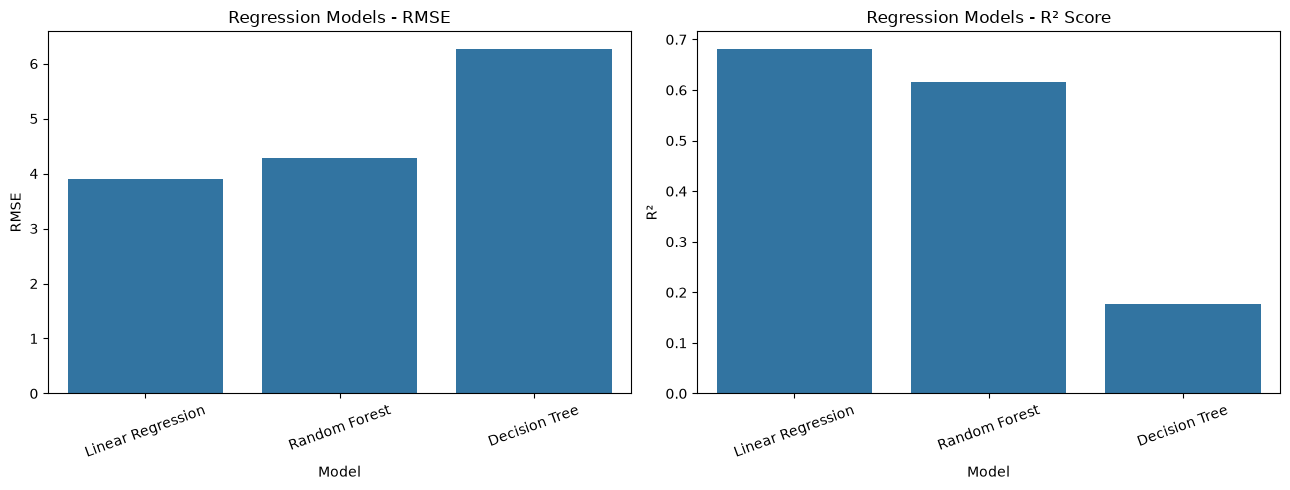

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=regression_df,
    x="Model",
    y="RMSE",
    ax=axes[0]
)
axes[0].set_title("Regression Models - RMSE")
axes[0].set_xlabel("Model")
axes[0].set_ylabel("RMSE")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=regression_df,
    x="Model",
    y="R2",
    ax=axes[1]
)
axes[1].set_title("Regression Models - R² Score")
axes[1].set_xlabel("Model")
axes[1].set_ylabel("R²")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

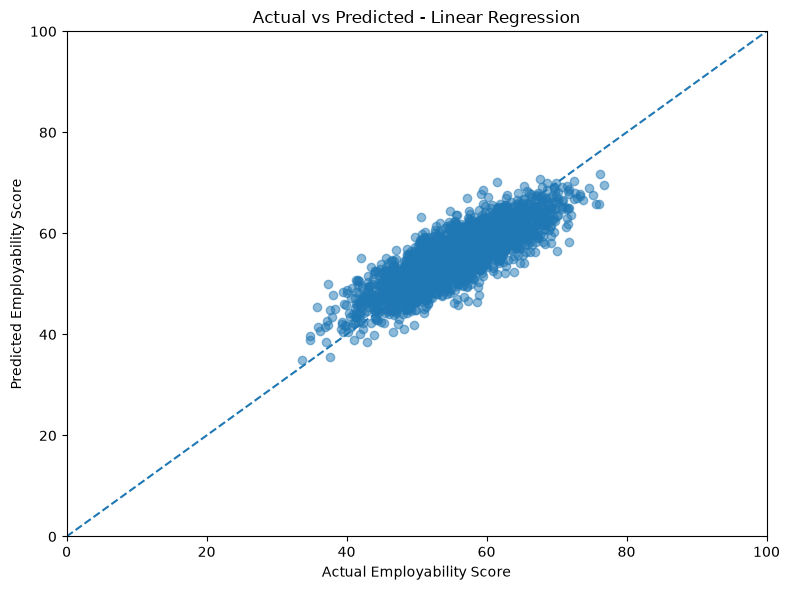

Best regression model: Linear Regression


In [28]:
best_regression_name = regression_df.iloc[0]["Model"]
best_regression_model = trained_regressors[best_regression_name]

predicted_scores = best_regression_model.predict(X_val)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_val_employability,
    predicted_scores,
    alpha=0.5
)

plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--"
)

plt.xlabel("Actual Employability Score")
plt.ylabel("Predicted Employability Score")
plt.title(f"Actual vs Predicted - {best_regression_name}")

plt.xlim(0, 100)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

print("Best regression model:", best_regression_name)

In [29]:
regression_path = REPORT_DIR / "baseline_regression_results.csv"

regression_df.to_csv(
    regression_path,
    index=False
)

print("Regression results saved successfully!")
print(regression_path)

Regression results saved successfully!
d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\reports\evaluation\baseline_regression_results.csv


In [30]:
# Combine classification and regression results

baseline_results = pd.concat(
    [classification_df, regression_df],
    ignore_index=True,
    sort=False
)

baseline_path = REPORT_DIR / "baseline_model_results.csv"

baseline_results.to_csv(
    baseline_path,
    index=False
)

print("BASELINE MODEL COMPARISON")
print("=" * 80)

display(baseline_results.round(4))

print("\nSaved to:", baseline_path)

BASELINE MODEL COMPARISON


,Task,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,F1_Weighted,ROC_AUC,MAE,MSE,RMSE,R2
0,Career Domain,Logistic Regression,0.4244,0.3367,0.2689,0.2669,0.3663,0.6853,NaN,NaN,NaN,NaN
1,Career Domain,Decision Tree,0.2458,0.1848,0.1830,0.1835,0.2507,0.5114,NaN,NaN,NaN,NaN
2,Career Domain,Random Forest,0.4067,0.4027,0.2100,0.1716,0.2934,0.6456,NaN,NaN,NaN,NaN
3,Career Readiness,Logistic Regression,0.7769,0.7884,0.7640,0.7746,0.7766,0.9138,NaN,NaN,NaN,NaN
4,Career Readiness,Random Forest,0.7329,0.7688,0.6962,0.7207,0.7295,0.8848,NaN,NaN,NaN,NaN
5,Career Readiness,Decision Tree,0.5964,0.5940,0.5935,0.5937,0.5964,0.6863,NaN,NaN,NaN,NaN
6,Placement,Decision Tree,0.5747,0.5388,0.5385,0.5386,0.5736,0.5385,NaN,NaN,NaN,NaN
7,Placement,Logistic Regression,0.6493,0.6081,0.5538,0.5308,0.5947,0.6488,NaN,NaN,NaN,NaN
8,Placement,Random Forest,0.6516,0.6174,0.5490,0.5175,0.5864,0.6324,NaN,NaN,NaN,NaN
9,Employability Score,Linear Regression,NaN,NaN,NaN,NaN,NaN,NaN,3.1261,15.2211,3.9014,0.6819



Saved to: d:\Christ_college_work\2MSAIM\AML\Capstone Project\career-navigator\reports\evaluation\baseline_model_results.csv


In [31]:
baseline_summary = []

for task in classification_df["Task"].unique():

    task_data = classification_df[
        classification_df["Task"] == task
    ]

    best = task_data.loc[task_data["F1_Macro"].idxmax()]

    baseline_summary.append({
        "Task": task,
        "Best Model": best["Model"],
        "Accuracy": best["Accuracy"],
        "Macro F1": best["F1_Macro"],
        "ROC-AUC": best["ROC_AUC"]
    })

best_regression = regression_df.loc[
    regression_df["RMSE"].idxmin()
]

baseline_summary.append({
    "Task": "Employability Score",
    "Best Model": best_regression["Model"],
    "MAE": best_regression["MAE"],
    "RMSE": best_regression["RMSE"],
    "R2": best_regression["R2"]
})

baseline_summary_df = pd.DataFrame(baseline_summary)

display(baseline_summary_df.round(4))

baseline_summary_df.to_csv(
    REPORT_DIR / "baseline_best_models_summary.csv",
    index=False
)

,Task,Best Model,Accuracy,Macro F1,ROC-AUC,MAE,RMSE,R2
0,Career Domain,Logistic Regression,0.4244,0.2669,0.6853,NaN,NaN,NaN
1,Career Readiness,Logistic Regression,0.7769,0.7746,0.9138,NaN,NaN,NaN
2,Placement,Decision Tree,0.5747,0.5386,0.5385,NaN,NaN,NaN
3,Employability Score,Linear Regression,NaN,NaN,NaN,3.1261,3.9014,0.6819


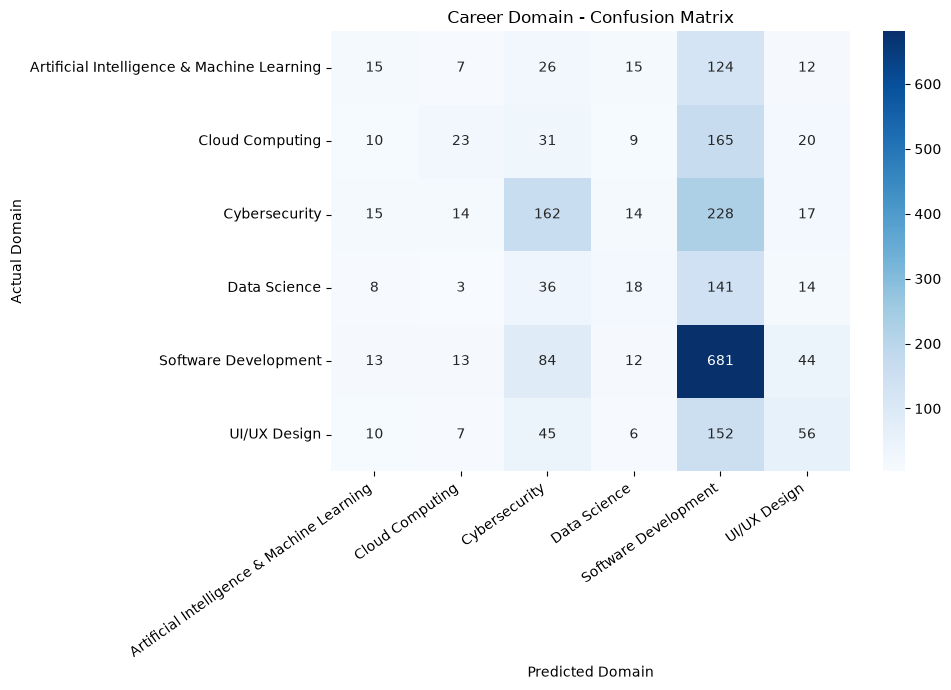

In [32]:
# Career Domain - Confusion Matrix Analysis

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import joblib

best_domain_model = trained_classifiers["Career Domain"]["Logistic Regression"]

domain_predictions = best_domain_model.predict(X_val)

domain_encoder = joblib.load(
    MODEL_DIR / "domain_encoder.joblib"
)

domain_names = domain_encoder.classes_

cm = confusion_matrix(
    y_val_domain,
    domain_predictions,
    labels=np.arange(len(domain_names))
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=domain_names,
    yticklabels=domain_names
)

plt.title("Career Domain - Confusion Matrix")
plt.xlabel("Predicted Domain")
plt.ylabel("Actual Domain")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [33]:
# Career Domain - Classification Report

domain_report = classification_report(
    y_val_domain,
    domain_predictions,
    labels=np.arange(len(domain_names)),
    target_names=domain_names,
    output_dict=True,
    zero_division=0
)

domain_report_df = pd.DataFrame(domain_report).transpose()

display(domain_report_df.round(4))

domain_report_df.to_csv(
    REPORT_DIR / "career_domain_classification_report.csv"
)

print("Career domain classification report saved!")

,precision,recall,f1-score,support
Artificial Intelligence & Machine Learning,0.2113,0.0754,0.1111,199.0000
Cloud Computing,0.3433,0.0891,0.1415,258.0000
Cybersecurity,0.4219,0.3600,0.3885,450.0000
Data Science,0.2432,0.0818,0.1224,220.0000
Software Development,0.4567,0.8040,0.5825,847.0000
UI/UX Design,0.3436,0.2029,0.2551,276.0000
accuracy,0.4244,0.4244,0.4244,0.4244
macro avg,0.3367,0.2689,0.2669,2250.0000
weighted avg,0.3803,0.4244,0.3663,2250.0000


Career domain classification report saved!


In [34]:
# Consolidate all baseline model results

baseline_results = pd.concat(
    [classification_df, regression_df],
    ignore_index=True,
    sort=False
)

baseline_results.to_csv(
    REPORT_DIR / "baseline_model_results.csv",
    index=False
)

# Select best classification models by Macro F1

best_classification_models = (
    classification_df
    .sort_values("F1_Macro", ascending=False)
    .groupby("Task")
    .first()
    .reset_index()
)

# Select best regression model by RMSE

best_regression_model = regression_df.loc[
    regression_df["RMSE"].idxmin()
]

print("=" * 70)
print("CAREER NAVIGATOR - BASELINE MODEL SUMMARY")
print("=" * 70)

display(
    best_classification_models[
        ["Task", "Model", "Accuracy", "F1_Macro", "ROC_AUC"]
    ].round(4)
)

print("\nBest Employability Regression Model:")
display(
    pd.DataFrame([best_regression_model]).round(4)
)

print("\nAll baseline results saved successfully!")

CAREER NAVIGATOR - BASELINE MODEL SUMMARY


,Task,Model,Accuracy,F1_Macro,ROC_AUC
0,Career Domain,Logistic Regression,0.4244,0.2669,0.6853
1,Career Readiness,Logistic Regression,0.7769,0.7746,0.9138
2,Placement,Decision Tree,0.5747,0.5386,0.5385



Best Employability Regression Model:


,Task,Model,MAE,MSE,RMSE,R2
0,Employability Score,Linear Regression,3.1261,15.2211,3.9014,0.6819



All baseline results saved successfully!


In [36]:
# Verify all baseline model artifacts

expected_models = [
    "baseline_placement_logistic_regression.joblib",
    "baseline_placement_decision_tree.joblib",
    "baseline_placement_random_forest.joblib",

    "baseline_career_readiness_logistic_regression.joblib",
    "baseline_career_readiness_decision_tree.joblib",
    "baseline_career_readiness_random_forest.joblib",

    "baseline_career_domain_logistic_regression.joblib",
    "baseline_career_domain_decision_tree.joblib",
    "baseline_career_domain_random_forest.joblib",

    "baseline_employability_linear_regression.joblib",
    "baseline_employability_decision_tree.joblib",
    "baseline_employability_random_forest.joblib"
]

missing_models = []

for filename in expected_models:
    exists = (MODEL_DIR / filename).exists()

    print(f"{filename}: {'FOUND' if exists else 'MISSING'}")

    if not exists:
        missing_models.append(filename)

print("\nMissing models:", missing_models)
assert not missing_models, "Some baseline models are missing!"

print("\nALL 12 BASELINE MODELS VERIFIED!")

baseline_placement_logistic_regression.joblib: FOUND
baseline_placement_decision_tree.joblib: FOUND
baseline_placement_random_forest.joblib: FOUND
baseline_career_readiness_logistic_regression.joblib: FOUND
baseline_career_readiness_decision_tree.joblib: FOUND
baseline_career_readiness_random_forest.joblib: FOUND
baseline_career_domain_logistic_regression.joblib: FOUND
baseline_career_domain_decision_tree.joblib: FOUND
baseline_career_domain_random_forest.joblib: FOUND
baseline_employability_linear_regression.joblib: FOUND
baseline_employability_decision_tree.joblib: FOUND
baseline_employability_random_forest.joblib: FOUND

Missing models: []

ALL 12 BASELINE MODELS VERIFIED!
